In [25]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers,models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.optimizers import Adam

In [3]:
size=(224,224)
train_ds=tf.keras.utils.image_dataset_from_directory(
    r'C:\Users\prath\Downloads\LP IV Updated Datasets\Object Detection\Intel Image Classification',
    image_size=size,
    validation_split=0.2,
batch_size=16,
subset='training',
    seed=42
)
test_ds=tf.keras.utils.image_dataset_from_directory(r'C:\Users\prath\Downloads\LP IV Updated Datasets\Object Detection\Intel Image Classification',
    image_size=size,
    validation_split=0.2,
    batch_size=16,
    subset='validation',
    seed=42 )
class_names=train_ds.class_names

Found 12632 files belonging to 6 classes.
Using 10106 files for training.
Found 12632 files belonging to 6 classes.
Using 2526 files for validation.


In [9]:
base=VGG16(weights=r'C:\Users\prath\Downloads\LP IV Updated Datasets\Object Detection\vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5',
input_shape=(224,224,3),
           include_top=False
          )
base.trainable=False

In [10]:
model=models.Sequential([
    layers.Lambda(preprocess_input),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(class_names),activation='softmax')
])

In [11]:
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lambda_1 (Lambda)                    │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 7, 7, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ ?                           │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [12]:
history=model.fit(train_ds.take(100),validation_data=test_ds.take(10),epochs=3)
loss,accuracy=model.evaluate(test_ds.take(10))
loss
accuracy

Epoch 1/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 409s 4s/step - accuracy: 0.4550 - loss: 2.7885 - val_accuracy: 0.7688 - val_loss: 0.8213
Epoch 2/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 410s 4s/step - accuracy: 0.7563 - loss: 0.9243 - val_accuracy: 0.8687 - val_loss: 0.4481
Epoch 3/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 412s 4s/step - accuracy: 0.8144 - loss: 0.6873 - val_accuracy: 0.8687 - val_loss: 0.5289
10/10 ━━━━━━━━━━━━━━━━━━━━ 36s 4s/step - accuracy: 0.8813 - loss: 0.4241


0.8812500238418579

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 551ms/step


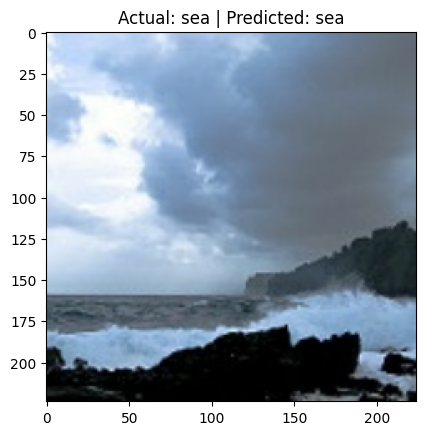

In [18]:
for images,labels in test_ds.take(1):
    prediction=tf.argmax(model.predict(images[:1])[0]).numpy()
    plt.imshow(images[0].numpy().astype('uint8'))
    plt.title('Actual: '+class_names[labels[0]]+" | "+ "Predicted: "+ class_names[prediction])
    plt.show()

In [26]:
base.trainable=True
for layer in base.layers[:-6]:
    layer.trainable=False
model.compile(optimizer=Adam(learning_rate=1e-5),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
model.fit(train_ds.take(100),validation_data=test_ds.take(10),epochs=1)


100/100 ━━━━━━━━━━━━━━━━━━━━ 565s 6s/step - accuracy: 0.8494 - loss: 0.4779 - val_accuracy: 0.8813 - val_loss: 0.3969


In [27]:
loss, accuracy = model.evaluate(test_ds.take(10))
print(loss)
print(accuracy)

10/10 ━━━━━━━━━━━━━━━━━━━━ 37s 4s/step - accuracy: 0.9000 - loss: 0.3319
0.331930011510849
0.8999999761581421
